**Import Libraries**

In [1]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

**Task 1: Load dataset and Check for Missing values**

In [2]:
# Load dataset
df = pd.read_csv("C:\\Users\\User\\Desktop\\PG230\\PG230_Bank_Loan_default_prediction\\data\\loan_data.csv")

# Check number of missing values per column
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

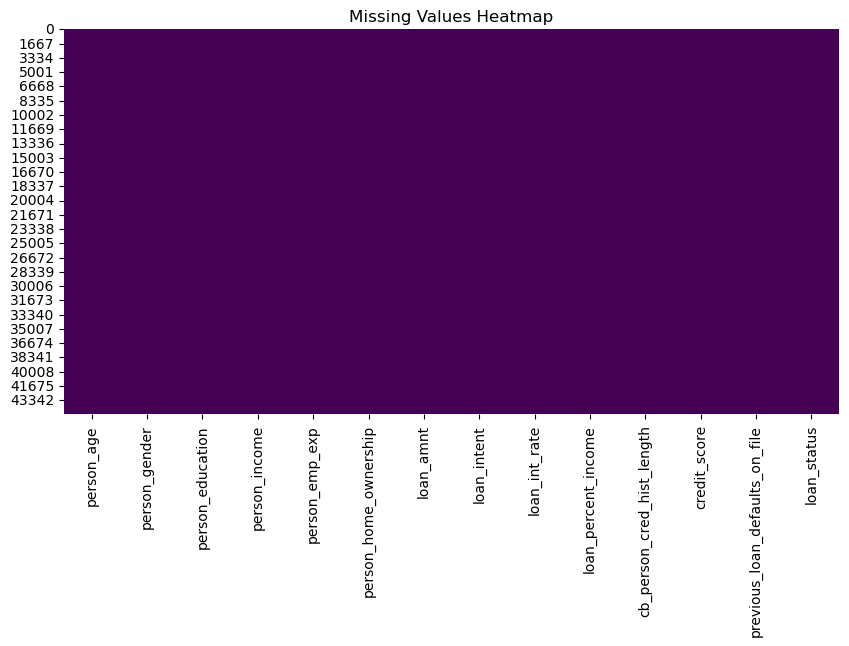

In [3]:
# heatmap to Visualize missing values
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()

In [4]:
# Check for duplicate rows
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows in dataset: {num_duplicates}")

Number of duplicate rows in dataset: 0


**Task 2: Outlier Detection & Removal**

* We focused on person_income because it has the largest range and potential extreme values, which can skew the model.

* loan_amnt and loan_int_rate may be large ranges, but extreme values are rarer or already cut off by the bank’s rules.

In [5]:
numeric_cols = ['person_age','person_income','person_emp_exp',
                'loan_amnt','loan_int_rate','loan_percent_income',
                'cb_person_cred_hist_length','credit_score']

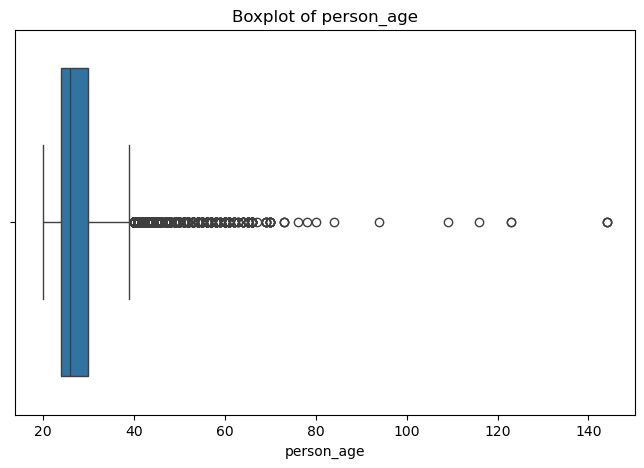

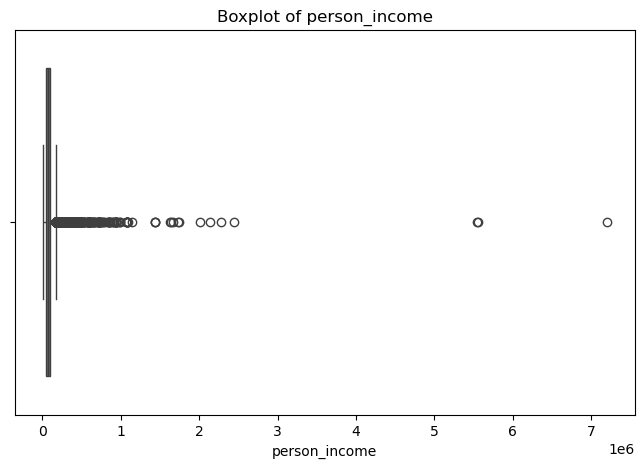

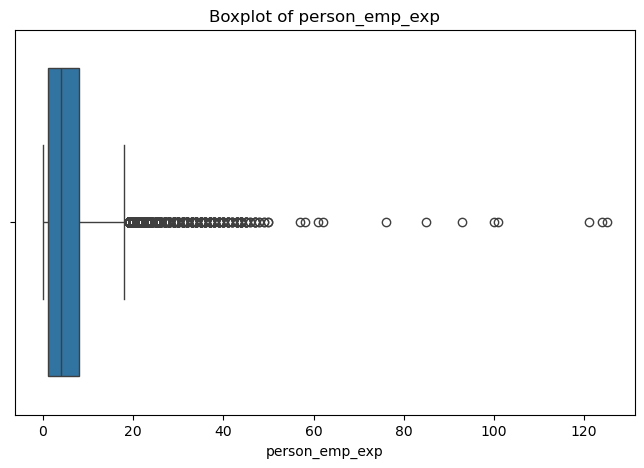

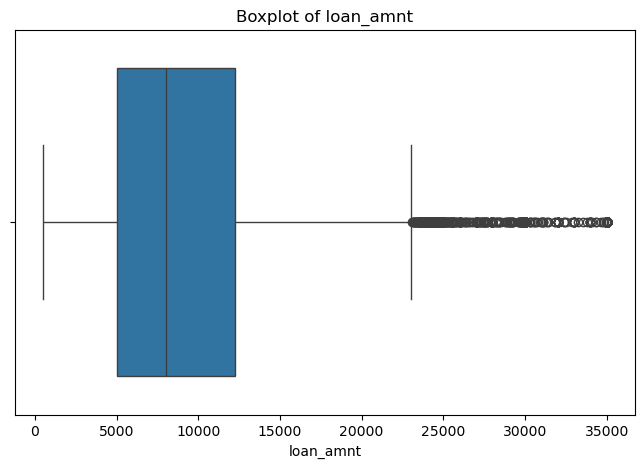

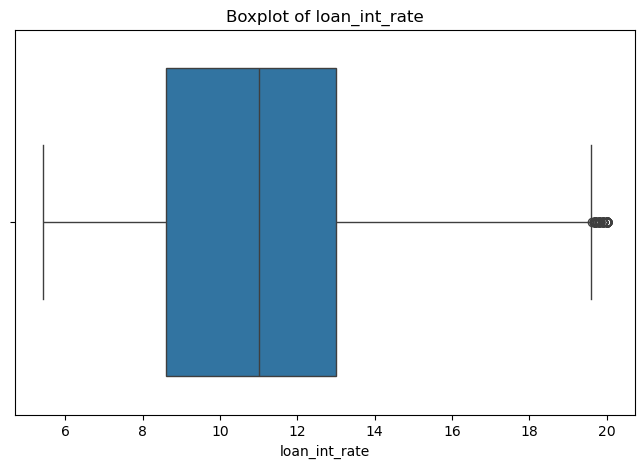

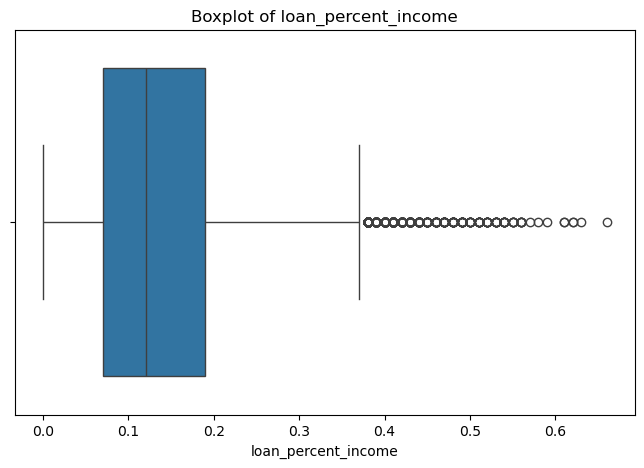

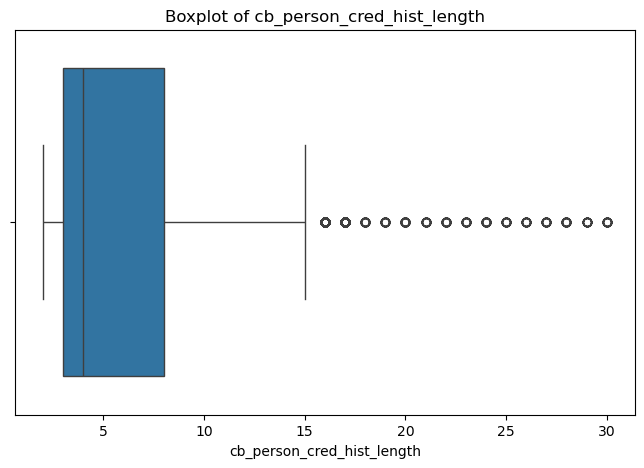

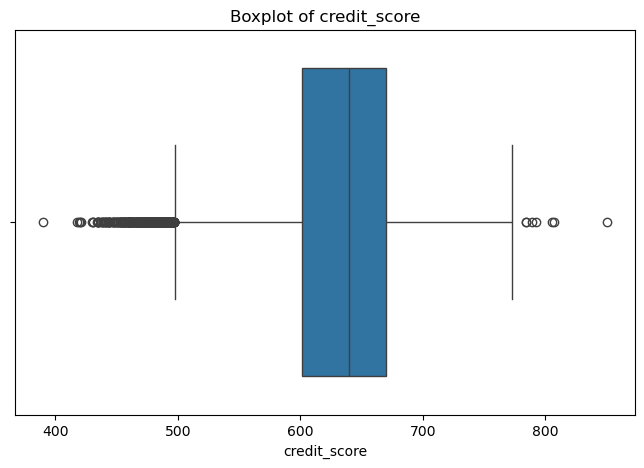

In [6]:
# 1. Visualize outliers with boxplot
for col in numeric_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [7]:
# 2. Use IQR method to detect outliers in person_income
Q1 = df['person_income'].quantile(0.25)
Q3 = df['person_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -25673.875
Upper Bound: 168667.125


In [8]:
# 3. Remove outliers
df_clean = df[(df['person_income'] >= lower_bound) & (df['person_income'] <= upper_bound)].copy()

In [9]:
# List all numeric columns except 'person_income'
other_cols = ['person_age', 'person_emp_exp', 'loan_amnt', 
              'loan_int_rate', 'loan_percent_income', 
              'cb_person_cred_hist_length', 'credit_score']

for col in other_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)].copy()

In [10]:
print("Original shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original shape: (45000, 14)
After outlier removal: (36082, 14)


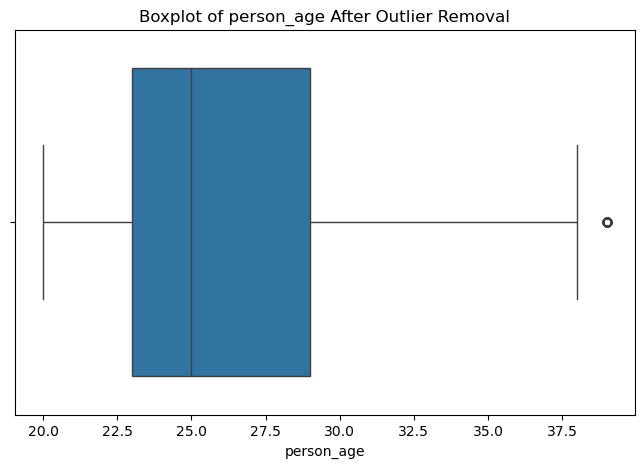

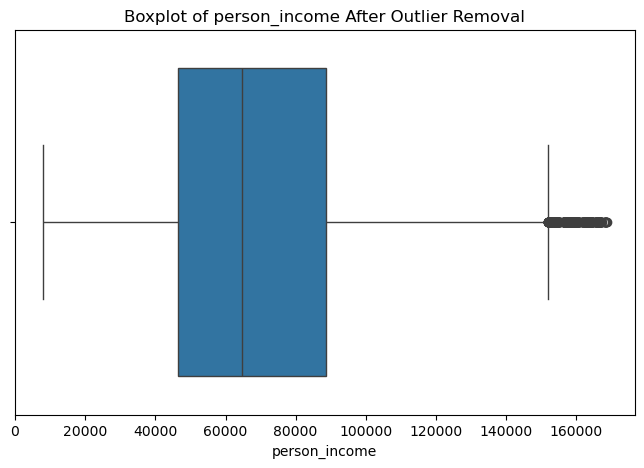

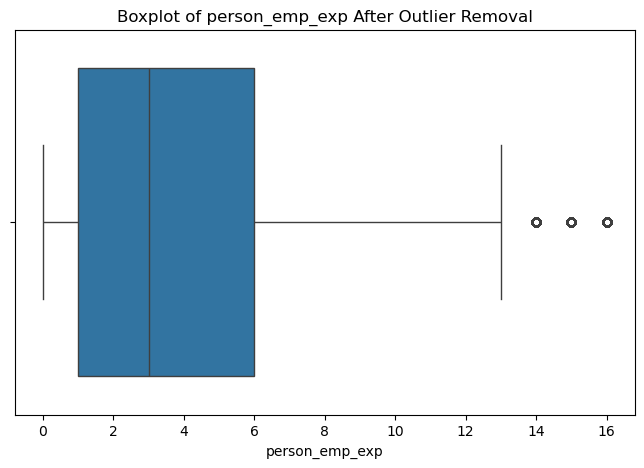

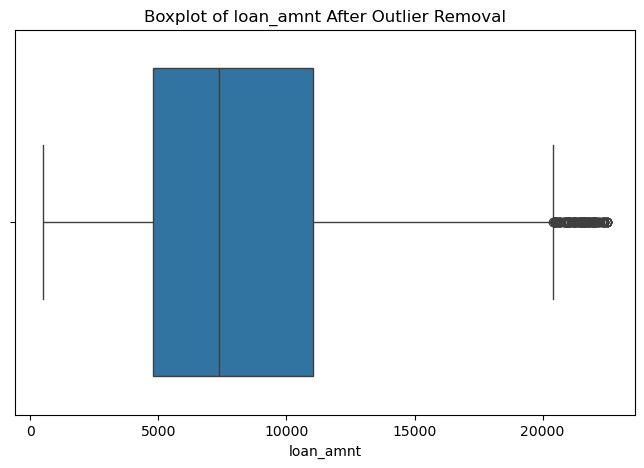

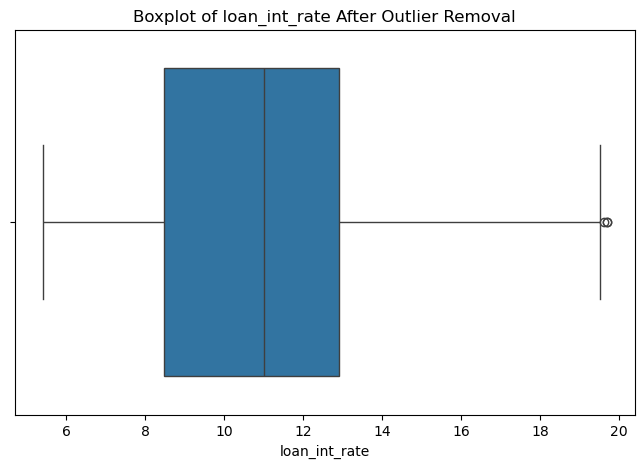

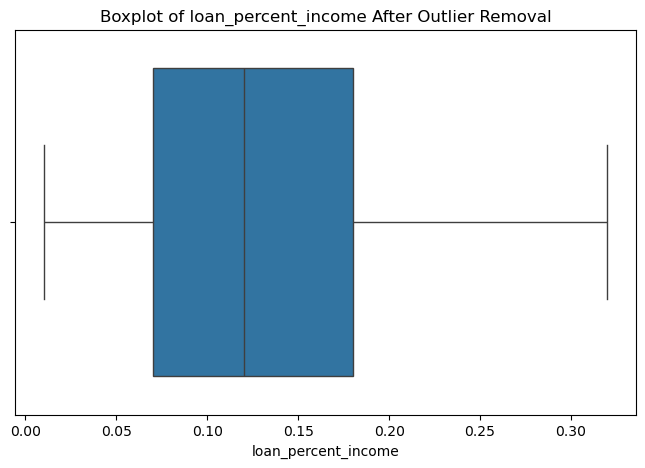

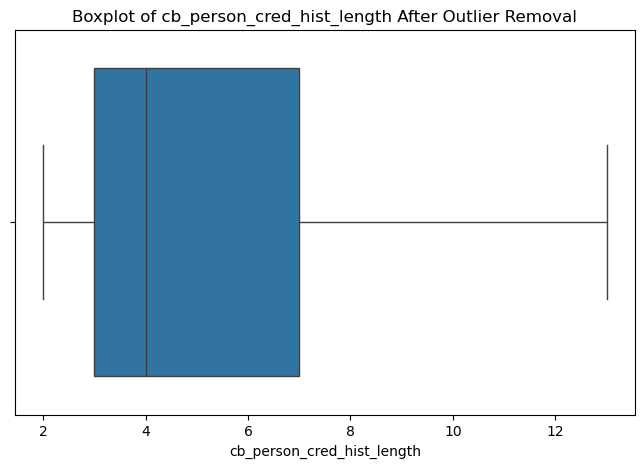

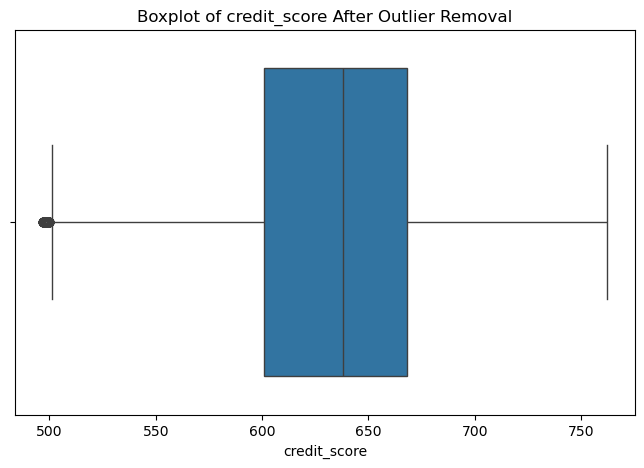

In [11]:
# Boxplots after outlier removal
for col in numeric_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Boxplot of {col} After Outlier Removal")
    plt.show()


**Task 3: Encoding Categorical Variables**

In [12]:
# Identify categorical columns
cat_cols = df_clean.select_dtypes(include='object').columns
print("Categorical Columns:", cat_cols.tolist())

Categorical Columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


* Label encoding is applied to peron_gender and previous_loan_defaults_on_file due to them being binary categories which means they only have two outputs.

In [13]:
# Label Encode binary categories
le = LabelEncoder()
df_clean['person_gender'] = le.fit_transform(df_clean['person_gender'])  # male/female
df_clean['previous_loan_defaults_on_file'] = le.fit_transform(df_clean['previous_loan_defaults_on_file'])  # yes/no

* One-hot encoding applied to person_education, person_home_ownership, loan_intent due to them having multiple outputs.

In [14]:
# One-Hot Encode multi-class categorical variables
df_clean = pd.get_dummies(df_clean,
                           columns=['person_education','person_home_ownership','loan_intent'],
                           drop_first=True)

* Shows correlations between all categorical features after encoding

In [15]:
label_cols = ['person_gender', 'previous_loan_defaults_on_file']
onehot_prefixes = ['person_education_', 'person_home_ownership_', 'loan_intent_']

encoded_cols = label_cols.copy()
for prefix in onehot_prefixes:
    encoded_cols.extend([col for col in df_clean.columns if col.startswith(prefix)])

df_encoded_bool = df_clean[encoded_cols].astype(int)

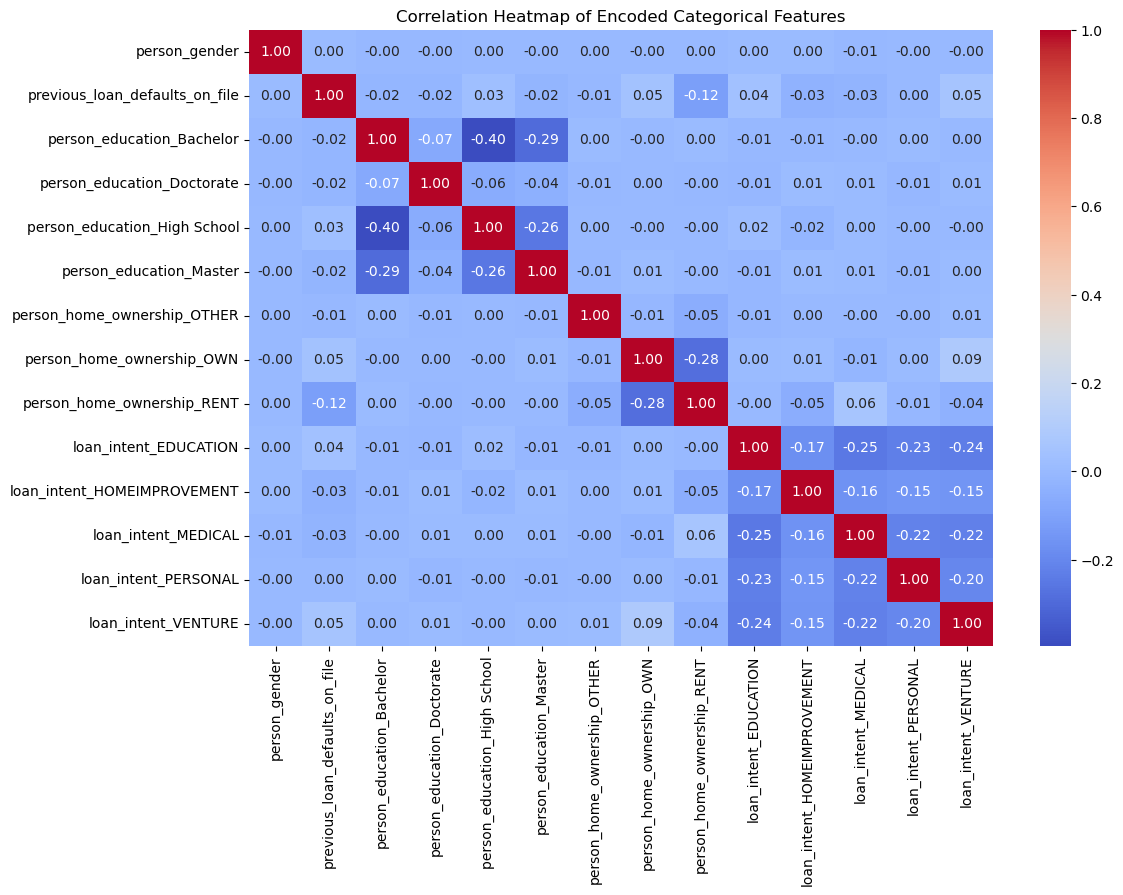

In [16]:
plt.figure(figsize=(12,8))
sns.heatmap(df_encoded_bool.corr(), cmap='coolwarm', annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Encoded Categorical Features")
plt.show()

In [17]:
# Display first five rows to check encoding
df_clean.head()

,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
1,21,0,12282,0,1000,11.14,0.08,2,504,1,...,True,False,False,True,False,True,False,False,False,False
5,21,0,12951,0,2500,7.14,0.19,2,532,0,...,True,False,False,True,False,False,False,False,False,True
9,21,0,12739,0,1600,14.74,0.13,3,640,0,...,True,False,False,True,False,False,False,False,False,True
19,24,0,14283,1,1750,10.99,0.12,2,679,0,...,False,True,False,False,False,True,False,False,False,False
23,24,0,13866,0,1500,7.29,0.11,3,600,1,...,False,False,False,True,False,False,False,False,True,False


**Task 4: Feature Scaling**

In [18]:
# Numeric columns
num_cols = ['person_age','person_income','person_emp_exp',
            'loan_amnt','loan_int_rate','loan_percent_income',
            'cb_person_cred_hist_length','credit_score']

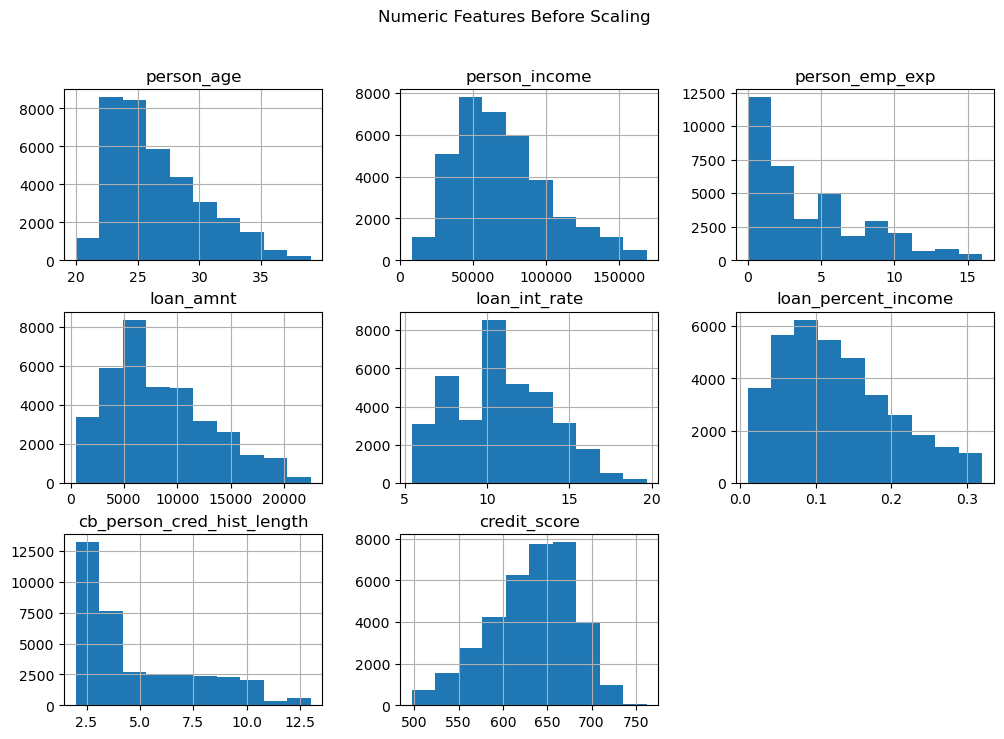

In [19]:
# Histograms before scaling
df_clean[num_cols].hist(figsize=(12,8))
plt.suptitle("Numeric Features Before Scaling")
plt.show()



* StandardScaling ensures that all features are scaled to equal ranges. It centers the data around 0 and scales by standard deviation, preserving the feature's distribution.



In [20]:
# Apply StandardScaler
scaler = StandardScaler()
df_clean[num_cols] = scaler.fit_transform(df_clean[num_cols])

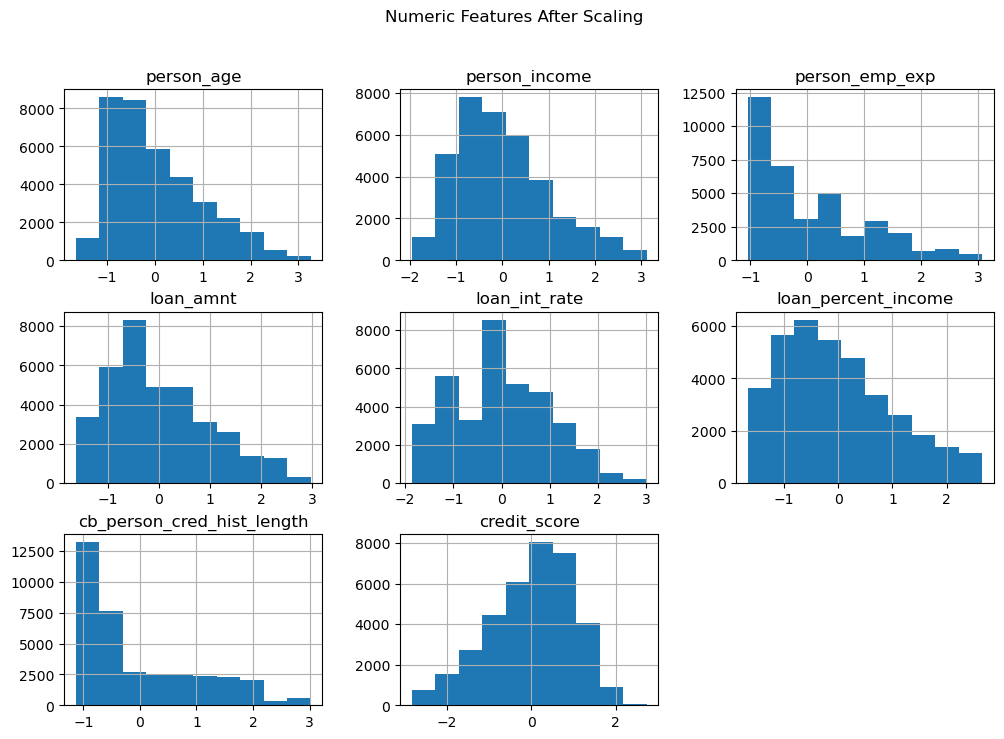

In [21]:
# Histograms after scaling
df_clean[num_cols].hist(figsize=(12,8))
plt.suptitle("Numeric Features After Scaling")
plt.show()

Task 5: Feature Engineering & EDA



* Debt-to income ratio measures the proportion of income used for the loan. It will help identify applicants with higher financial risk which will be valuable for predicting loan status.



In [22]:
# Debt-to-Income Ratio
df_clean['debt_to_income_ratio'] = df_clean['loan_amnt'] / df_clean['person_income']



* Age is divided into four categories (Young, Adult, Senior, Elder) for futher clarity. Then they are encoded using one-hot encoding.



In [23]:
# Age groups
bins = [18, 30, 50, 65, 100]
labels = ['Young','Adult','Senior','Elder']
df_clean['age_group'] = pd.cut(df_clean['person_age'], bins=bins, labels=labels)

In [24]:
# One-Hot Encode age_group
df_clean = pd.get_dummies(df_clean, columns=['age_group'], drop_first=True)

In [25]:
print("All columns in the dataset after feature engineering:")
print(df_clean.columns)

All columns in the dataset after feature engineering:
Index(['person_age', 'person_gender', 'person_income', 'person_emp_exp',
       'loan_amnt', 'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length', 'credit_score',
       'previous_loan_defaults_on_file', 'loan_status',
       'person_education_Bachelor', 'person_education_Doctorate',
       'person_education_High School', 'person_education_Master',
       'person_home_ownership_OTHER', 'person_home_ownership_OWN',
       'person_home_ownership_RENT', 'loan_intent_EDUCATION',
       'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL',
       'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio',
       'age_group_Adult', 'age_group_Senior', 'age_group_Elder'],
      dtype='object')




* A correlation heatmap is plotted to examin relationship between numeric features.


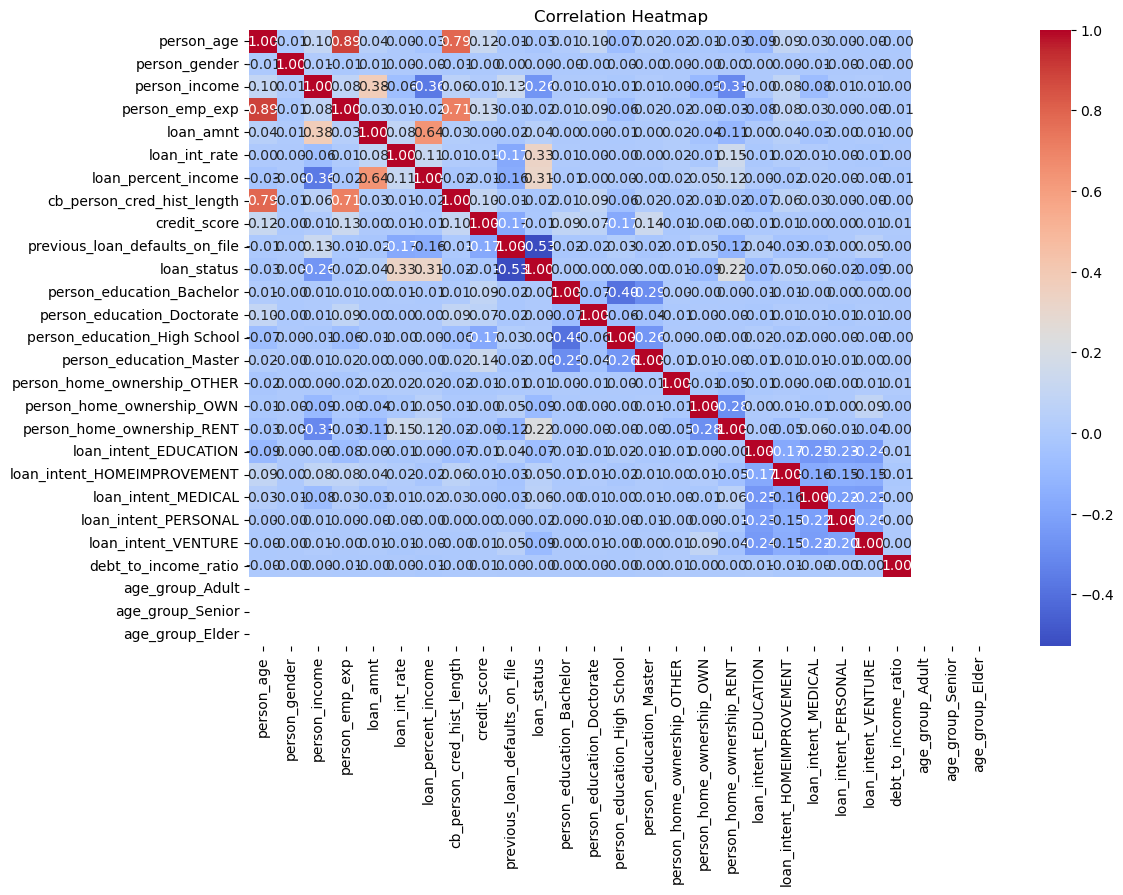

In [26]:
# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()



* We used a countplot to show how many applicants defaulted and how many did not.








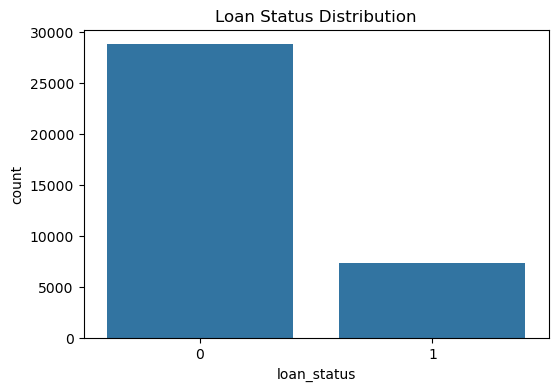

In [27]:
# Class balance
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df_clean)
plt.title("Loan Status Distribution")
plt.show()

* We used a boxplot to quickly see if people who failed to pay back their loans (Defult) typically had more debt than people who paid them back (No defult).

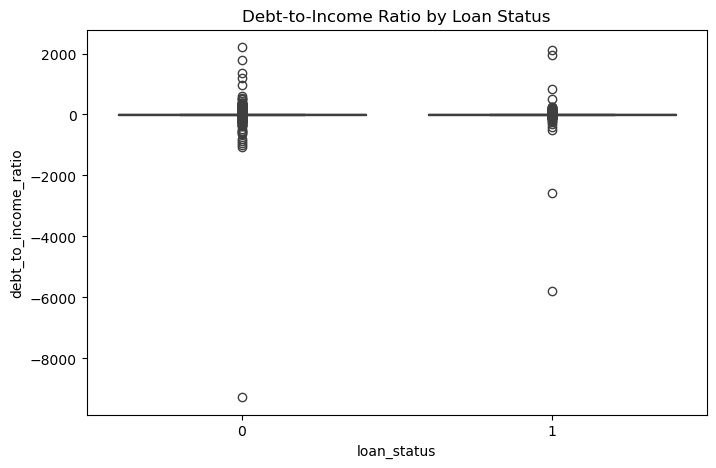

In [28]:
# Debt-to-Income vs Loan Status
plt.figure(figsize=(8,5))
sns.boxplot(x='loan_status', y='debt_to_income_ratio', data=df_clean)
plt.title("Debt-to-Income Ratio by Loan Status")
plt.show()

**Task 6: Feature Selection**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import VarianceThreshold

In [30]:
# Seperate features and the target variable
X = df_clean.drop('loan_status', axis=1)
y = df_clean['loan_status']

In [31]:
print("Original shape:", df_clean.shape)
print(df_clean)

Original shape: (36082, 27)
       person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
1       -1.397814              0      -1.828331       -1.050160  -1.521430   
5       -1.397814              0      -1.807177       -1.050160  -1.207890   
9       -1.397814              0      -1.813881       -1.050160  -1.396014   
19      -0.622076              0      -1.765060       -0.792289  -1.364660   
23      -0.622076              0      -1.778245       -1.050160  -1.416916   
...           ...            ...            ...             ...        ...   
44990    1.187981              1       2.109884        1.270682   0.844542   
44993    0.153663              0      -1.093809       -0.018675  -0.685323   
44995    0.153663              1      -0.699861        0.497068   1.404943   
44997    1.705140              1      -0.416202        0.754939  -1.151244   
44999   -0.622076              1      -0.584829       -0.792289  -0.337294   

       loan_int_rate  loan_percent_

**Select method 1: Variance Threshold**

In [32]:
# Apply Variance Threshold
var_thresh = VarianceThreshold(threshold=0.01)  # threshold=0 means drop only constant cols
X_var_selected = var_thresh.fit_transform(X)
kept_after_var = X.columns[var_thresh.get_support()]

print("Features kept after Variance Threshold:", kept_after_var.tolist())

# Identify dropped ones
dropped_by_var = [col for col in X.columns if col not in kept_after_var]
print("Features dropped by Variance Threshold:", dropped_by_var)

Features kept after Variance Threshold: ['person_age', 'person_gender', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio']
Features dropped by Variance Threshold: ['person_home_ownership_OTHER', 'age_group_Adult', 'age_group_Senior', 'age_group_Elder']


In [33]:
#  dataframe after dropping low variance features
X_var_df = pd.DataFrame(X_var_selected, columns=kept_after_var)
print("Shape after VarianceThreshold:", X_var_df.shape)
print(X_var_df)

Shape after VarianceThreshold: (36082, 22)
       person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0       -1.397814            0.0      -1.828331       -1.050160  -1.521430   
1       -1.397814            0.0      -1.807177       -1.050160  -1.207890   
2       -1.397814            0.0      -1.813881       -1.050160  -1.396014   
3       -0.622076            0.0      -1.765060       -0.792289  -1.364660   
4       -0.622076            0.0      -1.778245       -1.050160  -1.416916   
...           ...            ...            ...             ...        ...   
36077    1.187981            1.0       2.109884        1.270682   0.844542   
36078    0.153663            0.0      -1.093809       -0.018675  -0.685323   
36079    0.153663            1.0      -0.699861        0.497068   1.404943   
36080    1.705140            1.0      -0.416202        0.754939  -1.151244   
36081   -0.622076            1.0      -0.584829       -0.792289  -0.337294   

       loan_int_rate

**Select method 2: Random Forest**

* We used a barplot to visualize the feature importance base on Random forest.


Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_HOMEIMPROVEMENT', 'debt_to_income_ratio'],
      dtype='object')


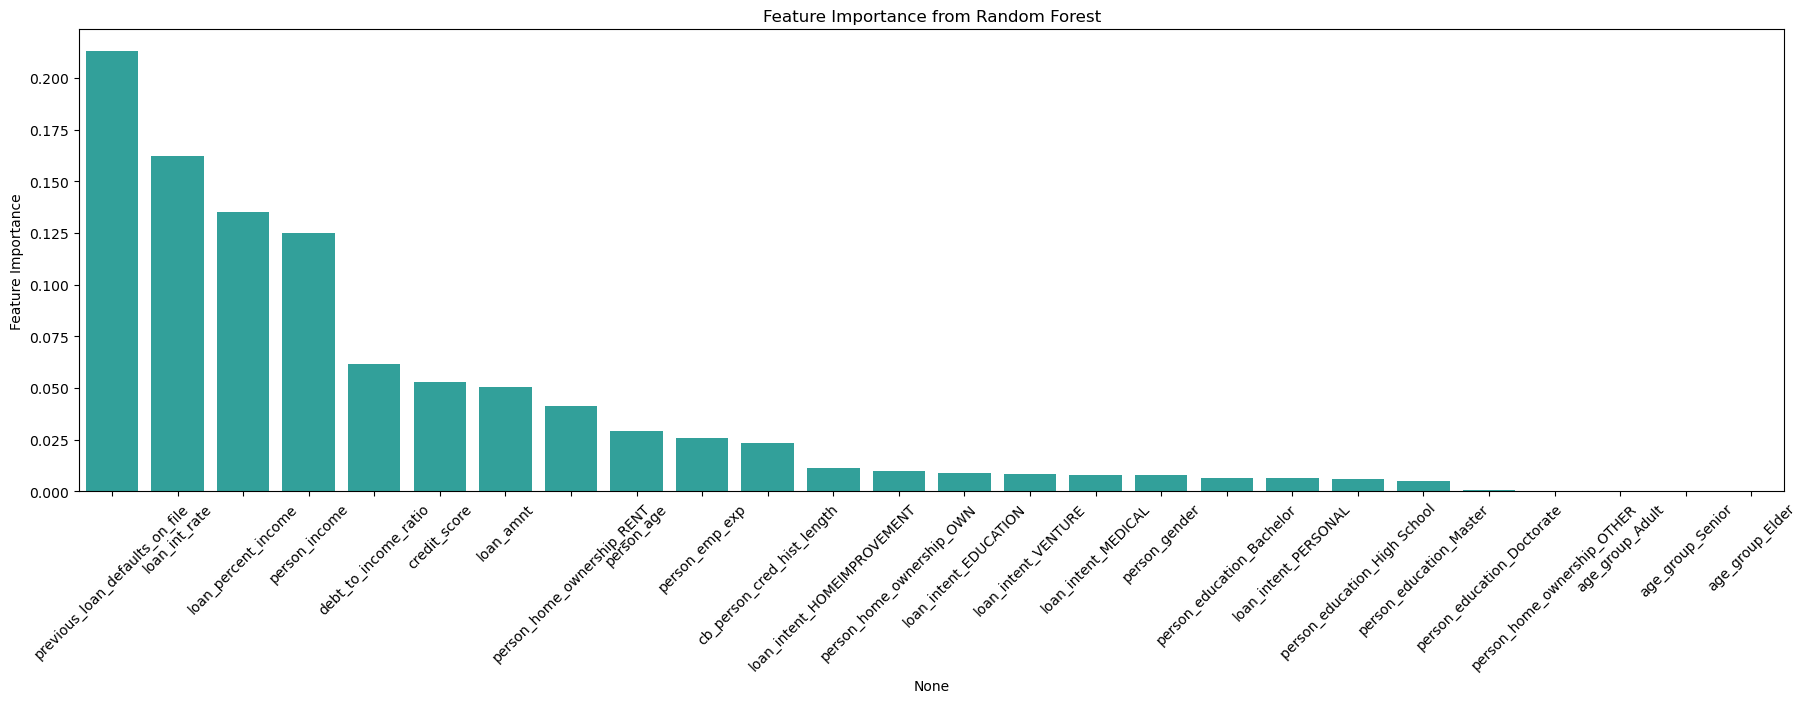

In [34]:
# Model-Based Feature Selection with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(22,6))
sns.barplot(x=importances.index, y=importances.values, color="lightseagreen")
plt.xticks(rotation=45)
plt.ylabel("Feature Importance")
plt.title("Feature Importance from Random Forest")
plt.show()

In [35]:
# Train Random Forest on variance-thresholded features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_var_df, y)

# Select features above median importance
model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X_var_df.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


In [36]:
# Create dataset with only selected features
X_final = selected_features.copy()
print(X_final)

Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


**Final output after feature selection**

In [37]:
# Create dataset with only selected features
X_final_df = X_var_df[X_final]

df_final = X_final_df.copy()
df_final['Loan_Status'] = y.values  # add target


In [38]:
print(df_final)

       person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0       -1.397814      -1.828331       -1.050160  -1.521430       0.088373   
1       -1.397814      -1.807177       -1.050160  -1.207890      -1.277767   
2       -1.397814      -1.813881       -1.050160  -1.396014       1.317900   
3       -0.622076      -1.765060       -0.792289  -1.364660       0.037143   
4       -0.622076      -1.778245       -1.050160  -1.416916      -1.226537   
...           ...            ...             ...        ...            ...   
36077    1.187981       2.109884        1.270682   0.844542       2.062446   
36078    0.153663      -1.093809       -0.018675  -0.685323       1.690173   
36079    0.153663      -0.699861        0.497068   1.404943       1.632112   
36080    1.705140      -0.416202        0.754939  -1.151244      -0.294146   
36081   -0.622076      -0.584829       -0.792289  -0.337294       2.106846   

       loan_percent_income  cb_person_cred_hist_length  credit_

After feature selection we were able to reduct the number of columns to 12 from 27 (22 was after encoding and feature engineering originally it was just 14 columns)